# Debiasing importance rankings through orthogonalization

This native Julia companion preserves the original experiment, observations, sample sizes, parameters and decision rules. Fixed public NumPy draws, fold assignments, permutations and bootstrap primitives replay the original seeded experiments. The supplied native binary Gini forest preserves the chapter’s unbalanced bootstrap classifier, Float32 split inputs, distinct-observation leaf limits and weighted leaf probabilities; feature-importance calculations use the native RiskLabAI caller-estimator interfaces. Rolling sums retain the public compensated arithmetic, and principal-component signs follow the public divide-and-conquer eigensolver convention before classifier fitting. The original distinction between published methods and the released simplified calculations is preserved. Figures use the requested dark theme, and native outputs are saved under `outputs/julia`.

Standardization removes level and scale, and an eigenvector rotation turns correlated features into orthogonal component scores:

$$
Z_{tj}=\frac{X_{tj}-\mu_j}{\sigma_j},
\qquad
Z^{\mathsf T}ZW=W\Lambda,
\qquad
P=ZW,
\qquad
P^{\mathsf T}P=\Lambda.
$$

Here, $X_{tj}$ is feature $j$ at observation $t$; $\mu_j,\sigma_j$ are its sample mean and standard deviation; $Z$ is the standardized matrix. $W$ contains orthonormal eigenvectors; $\Lambda$ is diagonal with descending eigenvalues; $P$ contains the component scores; $\mathsf T$ denotes transpose.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("14_feature_importance");
using CSV, TOML, Printf
include(joinpath("..","support","BookForest.jl"))
using RiskLabAI.Features: feature_importance_mdi,feature_importance_mda,feature_importance_sfi,clustered_feature_importance_mdi,clustered_feature_importance_mda,orthogonal_features,calculate_weighted_tau,mdi_plus_importance,conditional_predictive_impact
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"


selected_features = ["Food","Beer","Hshld","Oil","Coal","Mines","Hardw","Softw","Chips","Banks","Insur","Fin"]
cluster_names = ["Consumer","Resources","Technology","Finance"]
clusters = [name=>collect(3index-2:3index) for (index,name) in enumerate(cluster_names)]
columns = [findfirst(==(name),industry_names) for name in selected_features]

"""Match the public rolling sum's separate add/remove Kahan compensations."""
function rolling_sum(values,window)
    all(isfinite,values) || throw(ArgumentError("complete finite observations are required"))
    result = fill(NaN,length(values))
    total,add_compensation,remove_compensation = 0.,0.,0.
    previous,consecutive = first(values),0
    for index in eachindex(values)
        if index>window
            correction = -values[index-window]-remove_compensation
            updated = total+correction
            remove_compensation = (updated-total)-correction
            total = updated
        end
        value = values[index]
        correction = value-add_compensation
        updated = total+correction
        add_compensation = (updated-total)-correction
        total = updated
        consecutive = value==previous ? consecutive+1 : 1
        previous = value
        if index>=window
            result[index] = consecutive>=window ? previous*window : total
        end
    end
    return result
end

public_x = hcat([rolling_sum(industry_returns[:,column],5)[5:end-1] for column in columns]...)
public_y = Int.(vec(mean(industry_returns[6:end,:];dims=2)).>0)
public_dates = industry_dates[6:end]
input_root = joinpath("..","data","chapter14_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
input_manifest = TOML.parsefile(manifest_path)["files"]
input_cache = Dict{String,DataFrame}()
audit_context = Ref("")
audit_fits,audit_nodes,audit_importances,audit_predictions = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
audit_models = IdDict{Any,Int}()
audit_calls = Dict{Int,Int}()

function primitive(name)
    filename = name*".csv"
    return get!(input_cache,filename) do
        path = joinpath(input_root,filename)
        CSV.read(path,DataFrame)
    end
end

forest(seed;trees=120,depth=5,leaf=10,features=1) = (;seed,trees,depth=depth===nothing ? typemax(Int32) : depth,leaf,features=features===nothing ? 0 : features)

function begin_audit(name)
    audit_context[] = name
    foreach(empty!,(audit_fits,audit_nodes,audit_importances,audit_predictions,audit_models,audit_calls))
    return nothing
end

function fit_native(estimator,x,y,weights)
    specification = estimator isa BookForest.ClassificationForest ? estimator.specification : estimator
    @assert weights===nothing || all(==(1),weights)
    plan = Matrix{Int}(primitive("forest_$(specification.seed)_$(length(y))_$(Int(weights!==nothing))"))
    fitted = BookForest.fit_forest(specification,x,y,plan[3:end,:],vec(plan[2,:]))
    fit = length(audit_fits)+1
    audit_models[fitted] = fit
    audit_calls[fit] = 0
    push!(audit_fits,(fit=fit,seed=specification.seed,observations=length(y),features=size(x,2),trees=specification.trees,depth=specification.depth,leaf=specification.leaf,max_features=specification.features,weighted=weights!==nothing))
    for (tree_index,tree) in enumerate(fitted.trees)
        for (index,node) in enumerate(tree.nodes)
            push!(audit_nodes,(fit=fit,tree=tree_index,node=index,feature=node.feature,threshold=node.threshold,left=node.left,right=node.right,count=node.count,mass=node.mass,positive=node.positive_mass,impurity=node.impurity))
        end
        for (feature,value) in enumerate(tree.importance)
            push!(audit_importances,(fit=fit,tree=tree_index,feature=feature,importance=value))
        end
    end
    return fitted
end

function predict_native(model,x)
    probabilities = BookForest.predict_proba(model,x)
    fit = audit_models[model]
    audit_calls[fit] += 1
    append!(audit_predictions,[(fit=fit,call=audit_calls[fit],row=index,p0=probabilities[index,1],p1=probabilities[index,2]) for index in axes(x,1)])
    return probabilities
end

function finish_audit()
    prefix = audit_context[]
    for (suffix,records) in [("fits",audit_fits),("nodes",audit_nodes),("tree_importance",audit_importances),("predictions",audit_predictions)]
        isempty(records) || save_data(DataFrame(records),paths,prefix*"_"*suffix)
    end
    return nothing
end

function saved_importance(name,result,labels)
    save_data(DataFrame(Feature=labels,Mean=result.mean,StandardDeviation=result.std),paths,name*"_importance")
    finish_audit()
    return result
end

function fixed_folds(seed)
    membership = primitive("folds_$(seed)").fold
    return [(findall(!=(fold),membership),findall(==(fold),membership)) for fold in 1:maximum(membership)]
end

function mdi(name,x,y,estimator;groups=nothing,labels=string.(axes(x,2)))
    begin_audit(name)
    options = (;fit_estimator=fit_native,tree_importances=BookForest.tree_importances)
    result = groups===nothing ? feature_importance_mdi(estimator,x,y;options...) : clustered_feature_importance_mdi(estimator,x,y,groups;options...)
    return saved_importance(name,result,labels)
end

function mda(name,x,y,estimator,seed;groups=nothing,labels=string.(axes(x,2)))
    begin_audit(name)
    folds = fixed_folds(seed)
    values = Matrix{Int}(primitive("permutations_$(seed)"))
    permutations = [[values[values[:,1].==fold,column] for column in 2:size(values,2)] for fold in eachindex(folds)]
    options = (;fit_estimator=fit_native,predict_proba=predict_native,estimator_classes=_->[0,1],folds,permutations,n_splits=length(folds),random_state=seed)
    result = groups===nothing ? feature_importance_mda(estimator,x,y;options...) : clustered_feature_importance_mda(estimator,x,y,groups;options...)
    return saved_importance(name,result,labels)
end

function sfi(name,x,y,estimator;labels=string.(axes(x,2)))
    begin_audit(name)
    result = feature_importance_sfi(estimator,x,y;fit_estimator=fit_native,predict=(model,values)->Int.(predict_native(model,values)[:,2].>.5),scoring=:accuracy,n_splits=5)
    return saved_importance(name,result,labels)
end

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter12-"*replace(name,"_"=>"-"))
    return nothing
end

function standard_panels(frame,label,title,name)
    order = sortperm(frame.MDI)
    panels = []
    for (column,color) in zip(["MDI","MDA log-loss decrease","SFI accuracy"],[palette.cyan,palette.amber,palette.green])
        lower,upper = min(0,minimum(frame[!,column])),max(0,maximum(frame[!,column]))
        span = max(upper-lower,eps(Float64))
        panel = bar(1:nrow(frame),frame[order,column];orientation=:h,yticks=(1:nrow(frame),frame[order,label]),color,linealpha=0,alpha=.85,legend=false,title=column,xlabel="Score",ylims=(.4,nrow(frame)+.6),xlims=(lower-.04span,upper+.12span),left_margin=5Plots.mm)
        vline!(panel,[0.];color=palette.text,linewidth=.8,label=false)
        push!(panels,panel)
    end
    save_figure(plot(panels...;layout=(1,3),size=(1500,650),plot_title=title,plot_titlefontsize=13),paths,name)
    return nothing
end

public_frame = hcat(DataFrame(Date=public_dates,Target=public_y),DataFrame(public_x,selected_features))
save_data(public_frame,paths,"public_predictors");


## Public Orthogonal Directions

The retained dimension is the smallest number of principal directions that reaches the chosen share of total standardized variation:

$$
m=\min\left\{q:\frac{\sum_{r=1}^{q}\lambda_r}{\sum_{r=1}^{p}\lambda_r}\geq\gamma\right\},
\qquad
\gamma=0.90.
$$

Here, $\lambda_r$ is eigenvalue $r$ in descending order; $p$ is the original number of features; $q$ is a candidate retained count. $m$ is the selected count; $\gamma$ is the cumulative-variation threshold, set here to $0.90.$

Row,Quantity,Value
,String,Float64
1,Observations,1755.0
2,Original features,12.0
3,Retained components,7.0
4,Cumulative variation,0.921012
5,Largest absolute off-diagonal product,2.38387e-12
6,Weighted rank agreement,-0.128558


Row,Component,Eigenvalue,Variation share,Cumulative variation,MDI,Inverse rank
,String,Float64,Float64,Float64,Float64,Float64
1,PC_1,11367.1,0.540058,0.540058,0.144748,1.0
2,PC_2,2897.99,0.137685,0.677743,0.140003,0.5
3,PC_3,2183.43,0.103736,0.781479,0.142552,0.333333
4,PC_4,1141.19,0.0542186,0.835698,0.152101,0.25
5,PC_5,677.77,0.0322011,0.867899,0.129453,0.2
6,PC_6,600.4,0.0285253,0.896424,0.146038,0.166667
7,PC_7,517.535,0.0245883,0.921012,0.145105,0.142857


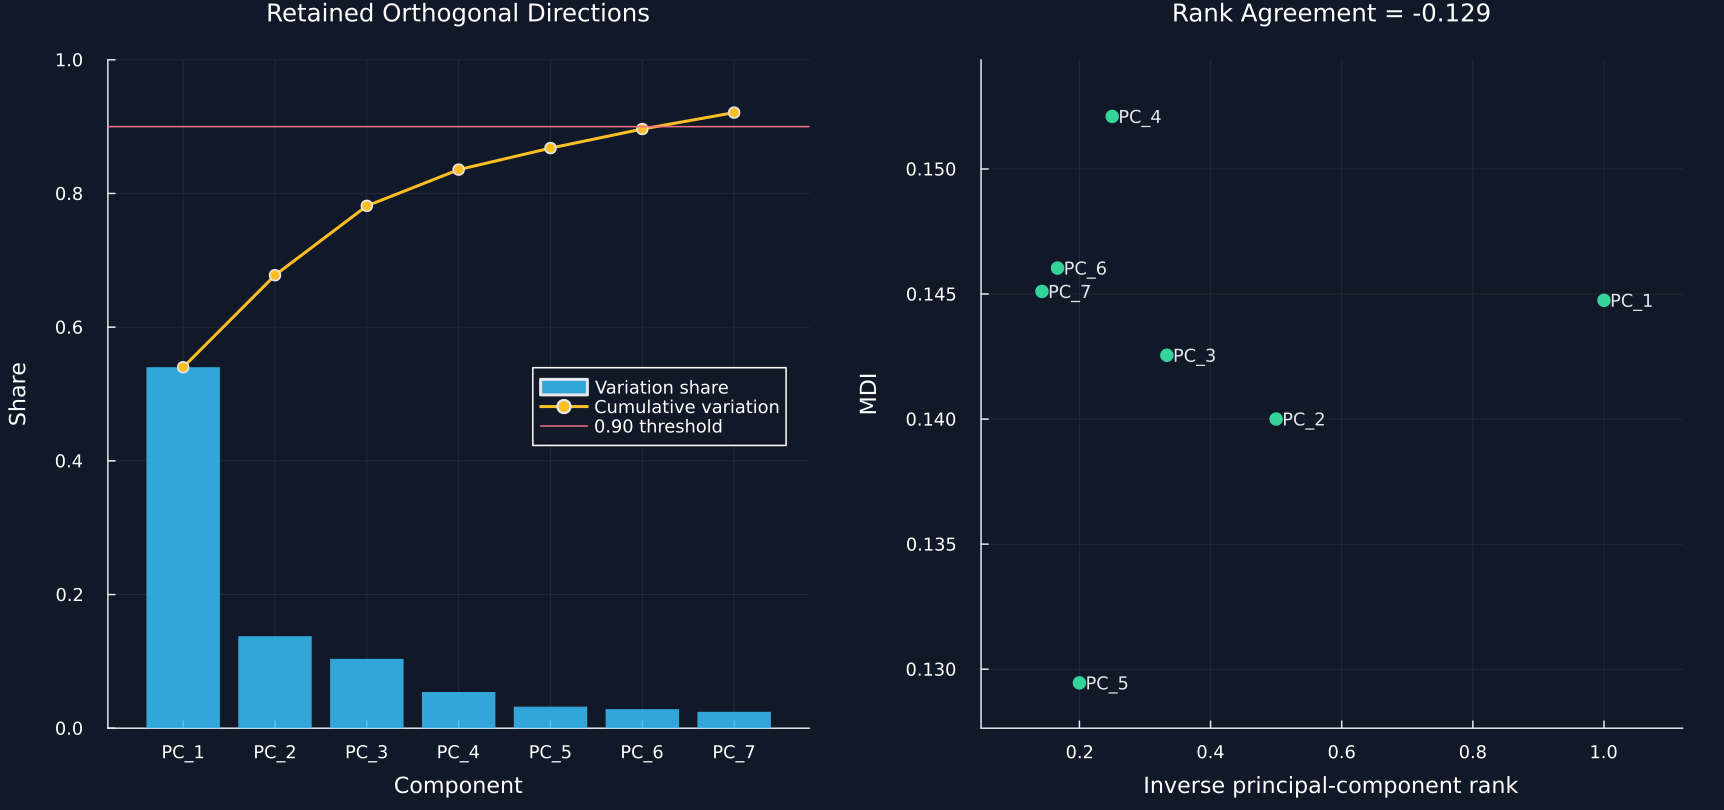

In [2]:
public_components,eigenvalues,eigenvectors,cumulative_variance = orthogonal_features(public_x;variance_threshold=.90)
normalized = (public_x.-mean(public_x;dims=1))./std(public_x;dims=1)
orientation = eigen(Symmetric(transpose(normalized)*normalized,:L);alg=LinearAlgebra.DivideAndConquer())
component_signs = [sign(dot(eigenvectors[:,index],orientation.vectors[:,end-index+1])) for index in axes(eigenvectors,2)]
public_components .*= transpose(component_signs)
eigenvectors .*= transpose(component_signs)
component_names = ["PC_$index" for index in axes(public_components,2)]
component_mdi = mdi("component_mdi",public_components,public_y,forest(1241);labels=component_names)
component_ranks = collect(axes(public_components,2))
weighted_tau = calculate_weighted_tau(component_mdi.mean,component_ranks)
component_gram = transpose(public_components)*public_components
off_diagonal = component_gram-Diagonal(diag(component_gram))
orthogonal_summary = DataFrame("Quantity"=>["Observations","Original features","Retained components","Cumulative variation","Largest absolute off-diagonal product","Weighted rank agreement"],"Value"=>[size(public_components,1),size(public_x,2),size(public_components,2),last(cumulative_variance),maximum(abs.(off_diagonal)),weighted_tau])
component_importance = DataFrame("Component"=>component_names,"Eigenvalue"=>eigenvalues,"Variation share"=>eigenvalues./(size(public_x,1)-1)./size(public_x,2),"Cumulative variation"=>cumulative_variance,"MDI"=>component_mdi.mean,"Inverse rank"=>1 ./ component_ranks)
table(orthogonal_summary,"orthogonal_summary","Public orthogonalization and rank-agreement summary.")
table(component_importance,"component_importance","Importance and unsupervised rank of the retained public components.")
save_data(DataFrame(public_components,component_names),paths,"public_components")
save_data(hcat(DataFrame(Feature=selected_features),DataFrame(eigenvectors,component_names)),paths,"public_component_loadings")
p1 = bar(component_ranks,component_importance[!,"Variation share"];color=palette.cyan,linealpha=0,alpha=.85,label="Variation share",xticks=(component_ranks,component_names),title="Retained Orthogonal Directions",xlabel="Component",ylabel="Share",legend=:right,ylims=(0,1))
plot!(p1,component_ranks,cumulative_variance;color=palette.amber,marker=:circle,label="Cumulative variation")
hline!(p1,[.9];color=palette.rose,linewidth=1,label="0.90 threshold")
lower,upper = extrema(component_mdi.mean)
span = upper-lower
p2 = scatter(1 ./ component_ranks,component_mdi.mean;color=palette.green,markersize=5,markerstrokewidth=0,legend=false,title=@sprintf("Rank Agreement = %.3f",weighted_tau),xlabel="Inverse principal-component rank",ylabel="MDI",xlims=(.05,1.12),ylims=(lower-.08span,upper+.1span))
for (index,name) in enumerate(component_names)
    annotate!(p2,1/index+.012,component_mdi.mean[index],text(name,8,:left,palette.text))
end
save_figure(plot(p1,p2;layout=(1,2),size=(1150,540)),paths,"public_orthogonal_rank")


## Weighted Rank Agreement

The released calculation compares component importances with inverse component rank and gives greater influence to agreement near the top:

$$
\tau_h=\operatorname{weightedtau}\!\left(a,r^{-1}\right),
\qquad
a=(a_1,\ldots,a_m),
\qquad
r=(1,\ldots,m).
$$

Here, $a_j$ is the importance of component $j$; $r_j$ is its eigenvalue rank; $r^{-1}$ is the elementwise inverse-rank vector. $m$ is the number of retained components; $\operatorname{weightedtau}$ is SciPy's hyperbolically weighted Kendall comparison; $\tau_h\in[-1,1]$ is its result.

## The Released Simplified Stump-Ridge Score

The released simplified score builds centered split indicators, fits a ridge model on in-bag rows, and measures each feature's partial prediction variance on out-of-bag rows:

$$
\phi_s(x_i)=\mathbf 1\!\left\{x_{i,j(s)}\leq c_s\right\}-\overline\phi_s,
\qquad
\widehat\beta_b=\arg\min_{\beta}\left\{\lVert y_{I_b}-\Phi_{I_b}\beta\rVert_2^2+\lVert\beta\rVert_2^2\right\},
\qquad
\operatorname{RLSI}_j=\frac{1}{B}\sum_{b=1}^{B}\operatorname{Var}_{i\in O_b}\!\left(\sum_{s:j(s)=j}\phi_s(x_i)\widehat\beta_{b,s}\right).
$$

Here, $s$ labels an internal split; $j(s)$ is its feature; $c_s$ is its threshold; $\phi_s$ is the centered split indicator. $\Phi$ collects all indicators; $I_b,O_b$ are the in-bag and out-of-bag rows for tree $b$; $y$ is the binary response; $\widehat\beta_b$ is the ridge coefficient vector. $B$ is the number of used trees; $\operatorname{RLSI}_j$ is the released library's simplified score for feature $j$, not the full MDI+ construction in the paper.

In [3]:
mdi_plus_rows = NamedTuple[]
for repetition in 1:12
    seed = 12029+repetition
    draws = primitive("bias_$(seed)")
    current_x = Matrix{Float64}(draws[:,[1,3,4,5,6,7]])
    current_y = Int.(xor.(Int.(draws.signal),draws.target_uniform.<.30))
    current_names = ["Binary signal","Binary noise","Four-level noise","Twenty-level noise","Continuous noise A","Continuous noise B"]
    bias_forest = forest(seed;depth=nothing,leaf=1)
    current_mdi = mdi("bias_$(seed)_mdi",current_x,current_y,bias_forest;labels=current_names)
    begin_audit("bias_$(seed)_plus")
    current_plus = mdi_plus_importance(bias_forest,current_x,current_y;fit_estimator=fit_native,tree_records=BookForest.tree_records,n_trees=50)
    finish_audit()
    save_data(DataFrame(Feature=current_names,MDI=current_mdi.mean,Score=current_plus),paths,"bias_$(seed)_scores")
    save_data(hcat(DataFrame(Target=current_y),DataFrame(current_x,current_names)),paths,"bias_$(seed)_predictors")
    push!(mdi_plus_rows,(repetition=repetition,mdi_signal=current_mdi.mean[1],mdi_noise=maximum(current_mdi.mean[2:end]),plus_signal=current_plus[1],plus_noise=maximum(current_plus[2:end]),mdi_first=argmax(current_mdi.mean)==1,plus_first=argmax(current_plus)==1))
end
mdi_plus_paths = DataFrame(mdi_plus_rows)
rename!(mdi_plus_paths,["Repetition","MDI signal","MDI largest noise","Released simplified score signal","Released simplified score largest noise","MDI ranks signal first","Released simplified score ranks signal first"])
mdi_plus_controlled = DataFrame("Method"=>["MDI","Released simplified stump-ridge score"],"Signal ranked first, share"=>[mean(mdi_plus_paths[!,"MDI ranks signal first"]),mean(mdi_plus_paths[!,"Released simplified score ranks signal first"])],"Mean signal score"=>[mean(mdi_plus_paths[!,"MDI signal"]),mean(mdi_plus_paths[!,"Released simplified score signal"])],"Mean largest-noise score"=>[mean(mdi_plus_paths[!,"MDI largest noise"]),mean(mdi_plus_paths[!,"Released simplified score largest noise"])])
save_data(mdi_plus_paths,paths,"mdi_plus_paths")
table(mdi_plus_controlled,"mdi_plus_controlled","Many-value noise comparison over twelve fixed-seed repetitions.")


Row,Method,"Signal ranked first, share",Mean signal score,Mean largest-noise score
,String,Float64,Float64,Float64
1,MDI,0.0,0.14649,0.281231
2,Released simplified stump-ridge score,1.0,0.0396747,0.0192557


## Testing conditional predictive impact

The released approximation replaces one feature by a ridge conditional mean plus Gaussian noise and measures the resulting held-out loss increase:

$$
\widetilde X_j=\widehat\mu_j(X_{-j})+\widehat\sigma_j\varepsilon,
\qquad
d_i=L\!\left(\widehat f,\widetilde z_i\right)-L\!\left(\widehat f,z_i\right),
\qquad
\widehat{\operatorname{CPI}}_j=\frac{1}{n}\sum_{i=1}^{n}d_i.
$$

Here, $X_{-j}$ contains all features except $j$; $\widehat\mu_j$ is its ridge prediction of feature $j$; $\widehat\sigma_j$ is residual scale. $\varepsilon$ is a standard-normal draw; $z_i,\widetilde z_i$ are original and replaced observations; $\widehat f$ is fitted without row $i$; $L$ is log loss. $d_i$ is the paired loss difference; $n$ is the number of held-out differences; $\widehat{\operatorname{CPI}}_j$ is their mean.

A one-sided paired t-test asks whether replacing feature $j$ increases expected held-out loss:

$$
t_j=\frac{\overline d_j}{s_{d,j}/\sqrt n},
\qquad
H_{0j}:\mathbb E[d_j]\leq0,
\qquad
H_{1j}:\mathbb E[d_j]>0.
$$

Here, $\overline d_j$ is the mean paired loss difference; $s_{d,j}$ is its sample standard deviation; $n$ is the number of differences. $t_j$ is the test statistic; $H_{0j}$ is the nonpositive-impact null; $H_{1j}$ is the positive-impact alternative; $\mathbb E$ denotes expectation.

Row,Design,Feature,Role,CPI,One-sided p-value,Below 0.05
,String,String,String,Float64,Float64,Bool
1,Joint Gaussian dependence,Direct signal,Direct signal,0.0865318,1.21272e-12,true
2,Joint Gaussian dependence,Correlated surrogate,Conditional null,0.00126324,0.378475,false
3,Joint Gaussian dependence,Second signal,Direct signal,0.250684,1.20161e-28,true
4,Joint Gaussian dependence,Independent noise,Conditional null,-0.000756346,0.654328,false
5,Nonlinear dependence,Direct signal,Direct signal,0.490641,2.4661e-57,true
6,Nonlinear dependence,Nonlinear surrogate,Conditional null,0.034542,1.99217e-10,true
7,Nonlinear dependence,Second signal,Direct signal,0.271362,3.0193e-33,true
8,Nonlinear dependence,Independent noise,Conditional null,0.00247707,0.137062,false


Row,Calculation,Main ingredients,Interpretation
,String,String,String
1,Published MDI+,"Augmented representation, chosen generalized linear model, sample splitting, chosen similarity measure",Paper method
2,Released simplified stump-ridge score,"Tree split indicators, fixed ridge fit, out-of-bag partial variance",Related simplified library calculation
3,Published CPI,"Valid knockoff sampler, out-of-sample paired loss",Paper method under valid knockoffs
4,Released conditional-impact approximation,"Ridge conditional mean, Gaussian residual draw, out-of-fold paired log loss",Approximation whose quality depends on the conditional model


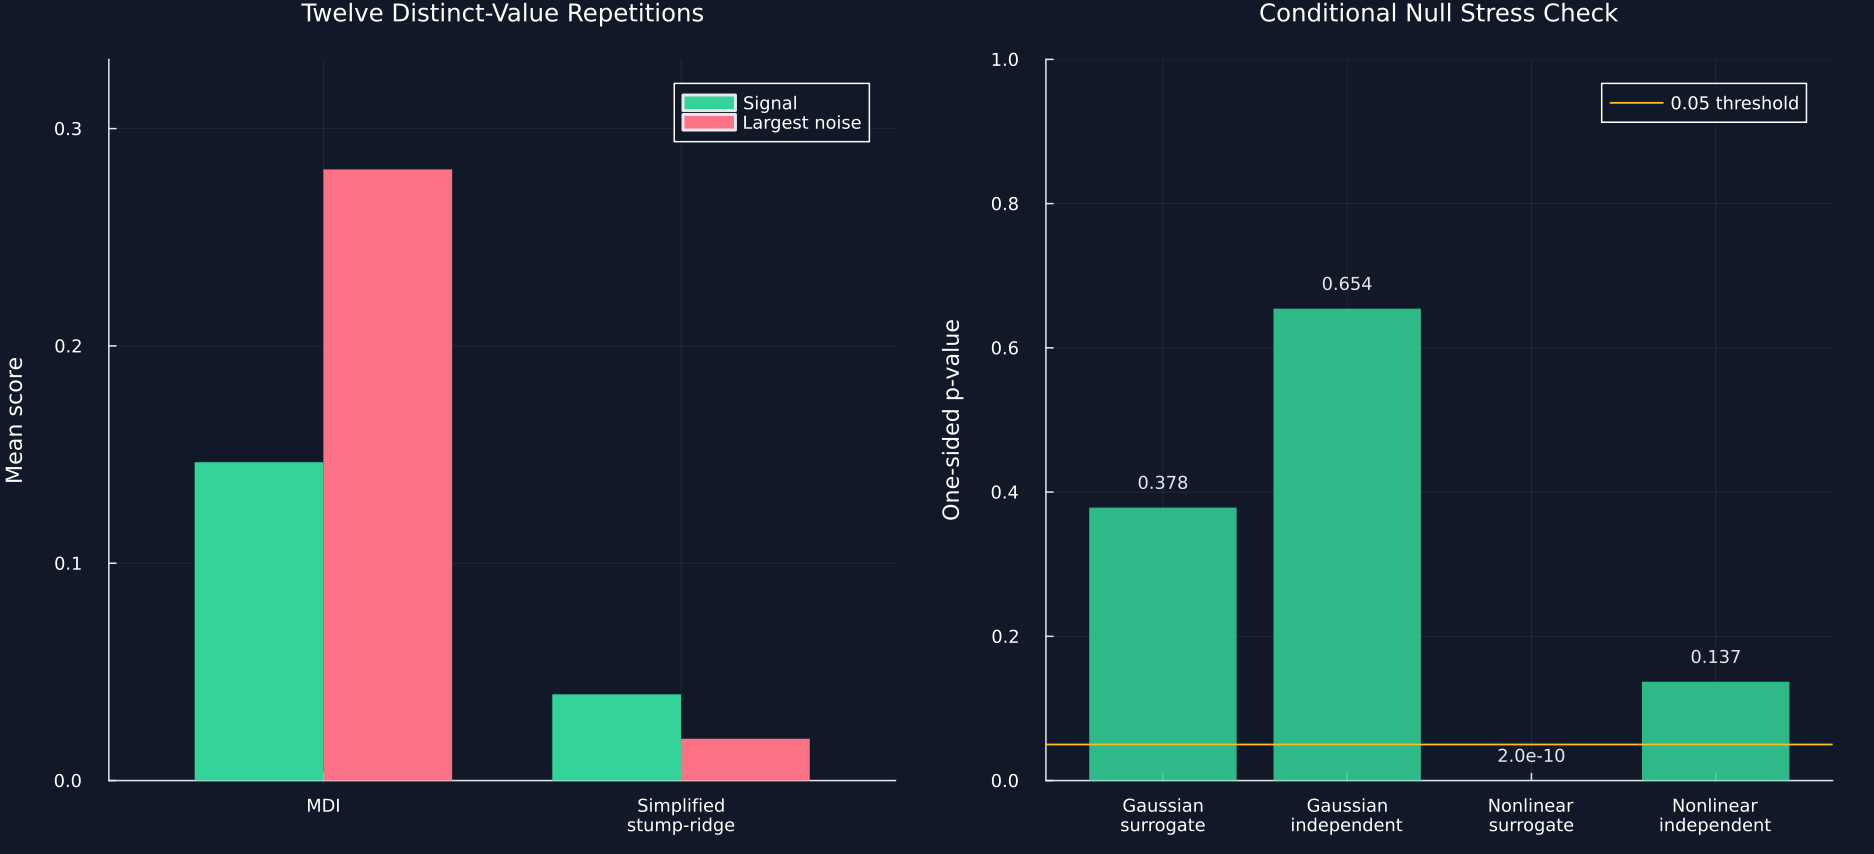

In [4]:
cpi_rows = NamedTuple[]
for (design,nonlinear,seed) in [("Joint Gaussian dependence",false,14001),("Nonlinear dependence",true,15001)]
    draws = primitive("cpi_$(seed)")
    surrogate = nonlinear ? draws.direct_signal.^2 .+.15draws.surrogate_noise : .9draws.direct_signal.+sqrt(1-.9^2).*draws.surrogate_noise
    current_x = hcat(draws.direct_signal,surrogate,draws.second_signal,draws.independent_noise)
    current_y = Int.((1.4draws.direct_signal.+.9draws.second_signal.+.9draws.target_noise).>0)
    current_names = ["Direct signal",nonlinear ? "Nonlinear surrogate" : "Correlated surrogate","Second signal","Independent noise"]
    splits = fixed_folds(seed)
    values = Matrix(primitive("gaussians_$(seed)"))
    gaussian_draws = [values[values[:,1].==fold,2:end] for fold in eachindex(splits)]
    begin_audit("cpi_$(seed)")
    result = conditional_predictive_impact(forest(seed;trees=80,depth=6,leaf=8,features=2),current_x,current_y;clone_estimator=identity,fit_estimator=fit_native,predict_proba=predict_native,estimator_classes=_->[0,1],random_state=seed,n_splits=4,splits,gaussian_draws)
    finish_audit()
    save_data(hcat(DataFrame(Target=current_y),DataFrame(current_x,current_names)),paths,"cpi_$(seed)_predictors")
    for (feature,name) in enumerate(current_names)
        role = feature in (2,4) ? "Conditional null" : "Direct signal"
        push!(cpi_rows,(design=design,feature=name,role=role,importance=result.importance[feature],p_value=result.p_value[feature],rejected=result.p_value[feature]<.05))
    end
end
cpi_controlled = DataFrame(cpi_rows)
rename!(cpi_controlled,["Design","Feature","Role","CPI","One-sided p-value","Below 0.05"])
table(cpi_controlled,"cpi_controlled","Conditional-impact approximation under linear-Gaussian and nonlinear dependence.")
method_scope = DataFrame("Calculation"=>["Published MDI+","Released simplified stump-ridge score","Published CPI","Released conditional-impact approximation"],"Main ingredients"=>["Augmented representation, chosen generalized linear model, sample splitting, chosen similarity measure","Tree split indicators, fixed ridge fit, out-of-bag partial variance","Valid knockoff sampler, out-of-sample paired loss","Ridge conditional mean, Gaussian residual draw, out-of-fold paired log loss"],"Interpretation"=>["Paper method","Related simplified library calculation","Paper method under valid knockoffs","Approximation whose quality depends on the conditional model"])
table(method_scope,"method_scope","Scope of the published methods and the released simplified calculations.")
p1 = bar([.82,1.82],mdi_plus_controlled[!,"Mean signal score"];bar_width=.36,color=palette.green,linealpha=0,label="Signal",xticks=([1,2],["MDI","Simplified
stump-ridge"]),title="Twelve Distinct-Value Repetitions",ylabel="Mean score",legend=:topright,xlims=(.4,2.6),ylims=(0,1.18maximum(Matrix(mdi_plus_controlled[:,3:4]))))
bar!(p1,[1.18,2.18],mdi_plus_controlled[!,"Mean largest-noise score"];bar_width=.36,color=palette.rose,linealpha=0,label="Largest noise")
null_rows = cpi_controlled[cpi_controlled.Role.=="Conditional null",:]
labels = ["Gaussian
surrogate","Gaussian
independent","Nonlinear
surrogate","Nonlinear
independent"]
colors = [value>=.05 ? palette.green : palette.rose for value in null_rows[!,"One-sided p-value"]]
p2 = bar(1:4,null_rows[!,"One-sided p-value"];color=colors,linealpha=0,alpha=.85,xticks=(1:4,labels),title="Conditional Null Stress Check",ylabel="One-sided p-value",label=false,legend=:topright,ylims=(0,1))
hline!(p2,[.05];color=palette.amber,linewidth=1.2,label="0.05 threshold")
for (index,value) in enumerate(null_rows[!,"One-sided p-value"])
    annotate!(p2,index,value+.035,text(value<.001 ? @sprintf("%.1e",value) : @sprintf("%.3f",value),8,palette.text))
end
save_figure(plot(p1,p2;layout=(1,2),size=(1250,570)),paths,"corrected_conditional_stress")


## Tests

In [5]:
@assert size(public_components)==(1755,7)
@assert length(eigenvalues)==length(cumulative_variance)==7 && size(eigenvectors)==(12,7)
@assert issorted(eigenvalues;rev=true)
@assert cumulative_variance[end-1]<.9
@assert cumulative_variance[end]>=.9
@assert maximum(abs.(off_diagonal))<1e-9
@assert length(component_mdi.mean)==length(component_mdi.std)==7
@assert sum(component_mdi.mean)≈1
@assert -1<=weighted_tau<=1
@assert weighted_tau<0
@assert size(component_importance)==(7,6)
@assert size(mdi_plus_paths)==(12,7)
@assert size(mdi_plus_controlled)==(2,4)
@assert sum(mdi_plus_paths[!,"MDI ranks signal first"])==0
@assert sum(mdi_plus_paths[!,"Released simplified score ranks signal first"])==12
@assert mdi_plus_controlled[2,"Mean signal score"]>mdi_plus_controlled[2,"Mean largest-noise score"]
@assert size(cpi_controlled)==(8,6)
@assert all(value->0<=value<=1,cpi_controlled[!,"One-sided p-value"])
@assert !cpi_controlled[2,"Below 0.05"]
@assert !cpi_controlled[4,"Below 0.05"]
@assert cpi_controlled[6,"Below 0.05"]
@assert all(cpi_controlled[cpi_controlled.Role.=="Direct signal","Below 0.05"])
@assert size(method_scope)==(4,3)
@assert isfile(joinpath(paths.figures,"public_orthogonal_rank.pdf"))
@assert isfile(joinpath(paths.figures,"corrected_conditional_stress.pdf"))
@assert isfile(joinpath(paths.tables,"orthogonal_summary.tex"))
@assert isfile(joinpath(paths.tables,"component_importance.tex"))
@assert isfile(joinpath(paths.tables,"mdi_plus_controlled.tex"))
@assert isfile(joinpath(paths.tables,"cpi_controlled.tex"))
@assert isfile(joinpath(paths.tables,"method_scope.tex"))
